In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords, wordnet
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("29-10-2026", "Task 2", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')

np.random.seed(42)
sample_size = min(2500, len(df))
sample_indices = np.random.choice(len(df), size=sample_size, replace=False)
df_sample = df.iloc[sample_indices].copy().reset_index(drop=True)
print(f"Sample corpus size: {len(df_sample)}")

Sample corpus size: 2500


In [3]:
contractions_dict = {
    "can't": "cannot", "won't": "will not", "n't": " not", "i'm": "i am",
    "it's": "it is", "they're": "they are", "we're": "we are", "i've": "i have",
    "you've": "you have", "didn't": "did not", "doesn't": "does not", "don't": "do not"
}

def expand_contractions(text):
    text_lower = text.lower()
    for contraction, expansion in contractions_dict.items():
        text_lower = text_lower.replace(contraction, expansion)
    return text_lower

def clean_domain_specs(text):
    text = re.sub(r"\b\d+'\d+\"?\b", " [MEASUREMENT] ", text)
    text = re.sub(r"\b\d+\s*(lbs?|pounds?|kg)\b", " [WEIGHT] ", text, flags=re.I)
    text = re.sub(r"\b\d{2}[a-f]\b", " [BRA_SIZE] ", text, flags=re.I)
    text = re.sub(r"\bsize\s*([0-9]{1,2}|xxs|xs|s|m|l|xl|xxl)\b", " [SIZE_SPEC] ", text, flags=re.I)
    text = re.sub(r"[^a-zA-Z\s\[\]]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

extracted_entities = []
sample_ner_texts = df_sample['Full_Review_Text'].head(300).tolist()

for text in sample_ner_texts:
    if not text.strip():
        continue
    words = word_tokenize(text)
    tags = nltk.pos_tag(words)
    chunks = nltk.ne_chunk(tags, binary=False)
    for chunk in chunks:
        if hasattr(chunk, 'label'):
            entity_name = " ".join(c[0] for c in chunk)
            entity_label = chunk.label()
            extracted_entities.append({'Entity_Text': entity_name, 'Entity_Label': entity_label})

df_entities = pd.DataFrame(extracted_entities)
df_entities_agg = df_entities.groupby(['Entity_Text', 'Entity_Label']).size().reset_index(name='Frequency').sort_values(by='Frequency', ascending=False).reset_index(drop=True)
entity_names_set = set(df_entities_agg['Entity_Text'].str.lower().tolist())

display(df_entities_agg.head(10))

,Entity_Text,Entity_Label,Frequency
0,Great,GPE,21
1,Cute,GPE,16
2,Beautiful,GPE,16
3,Gorgeous,GPE,8
4,Perfect,GPE,6
5,Super,GPE,5
6,Versatile,GPE,3
7,Adorable,GPE,2
8,Awesome,GPE,2
9,Love,GPE,2


In [4]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
standard_stopwords = set(stopwords.words('english'))

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

def pipeline_standard_stemming(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    tokens = word_tokenize(text)
    return " ".join([stemmer.stem(t) for t in tokens if t not in standard_stopwords and len(t) > 2])

def pipeline_standard_lemmatization(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    tokens = word_tokenize(text)
    return " ".join([lemmatizer.lemmatize(t) for t in tokens if t not in standard_stopwords and len(t) > 2])

retained_pos_prefixes = ('JJ', 'RB', 'NN', 'VB')
negation_tokens = {'not', 'never', 'no', 'cannot', 'neither', 'nor'}

def pipeline_advanced_preprocessing(text):
    text = expand_contractions(text)
    text = clean_domain_specs(text)
    tokens = word_tokenize(text)
    if not tokens:
        return ""
    tagged = nltk.pos_tag(tokens)
    processed_tokens = []
    i = 0
    n = len(tagged)
    while i < n:
        word, tag = tagged[i]
        word_lower = word.lower()
        if word_lower in entity_names_set:
            i += 1
            continue
        if word_lower in negation_tokens and i + 1 < n:
            next_word, next_tag = tagged[i + 1]
            if next_tag.startswith(retained_pos_prefixes):
                wn_pos = get_wordnet_pos(next_tag)
                lemmed_next = lemmatizer.lemmatize(next_word.lower(), wn_pos)
                processed_tokens.append(f"not_{lemmed_next}")
                i += 2
                continue
        if tag.startswith(retained_pos_prefixes) and len(word_lower) > 2:
            if word_lower not in standard_stopwords or word_lower in negation_tokens:
                wn_pos = get_wordnet_pos(tag)
                processed_tokens.append(lemmatizer.lemmatize(word_lower, wn_pos))
        i += 1
    return " ".join(processed_tokens)

df_sample['Text_Standard_Stemmed'] = df_sample['Full_Review_Text'].apply(pipeline_standard_stemming)
df_sample['Text_Standard_Lemmatized'] = df_sample['Full_Review_Text'].apply(pipeline_standard_lemmatization)
df_sample['Text_Advanced_Processed'] = df_sample['Full_Review_Text'].apply(pipeline_advanced_preprocessing)

print("Preprocessing transformations complete.")

Preprocessing transformations complete.


In [5]:
pipelines = [
    ('Raw Text', df_sample['Full_Review_Text']),
    ('Standard Stemming', df_sample['Text_Standard_Stemmed']),
    ('Standard Lemmatization', df_sample['Text_Standard_Lemmatized']),
    ('Advanced Context-Aware NLP', df_sample['Text_Advanced_Processed'])
]

benchmark_records = []
y_target = df_sample['Recommended IND'].values

for p_name, text_series in pipelines:
    vec = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))
    X_mat = vec.fit_transform(text_series)
    sparsity = 1.0 - (X_mat.nnz / (X_mat.shape[0] * X_mat.shape[1]))
    
    X_tr, X_te, y_tr, y_te = train_test_split(X_mat, y_target, test_size=0.25, random_state=42, stratify=y_target)
    clf = LogisticRegression(max_iter=500, random_state=42)
    clf.fit(X_tr, y_tr)
    
    preds = clf.predict(X_te)
    probs = clf.predict_proba(X_te)[:, 1]
    
    benchmark_records.append({
        'Pipeline': p_name,
        'Vocabulary_Size': len(vec.vocabulary_),
        'Matrix_Sparsity': round(sparsity, 4),
        'Accuracy': round(accuracy_score(y_te, preds), 4),
        'Macro_F1': round(f1_score(y_te, preds, average='macro'), 4),
        'ROC_AUC': round(roc_auc_score(y_te, probs), 4)
    })

df_bench = pd.DataFrame(benchmark_records)
display(df_bench)

,Pipeline,Vocabulary_Size,Matrix_Sparsity,Accuracy,Macro_F1,ROC_AUC
0,Raw Text,3000,0.9797,0.8368,0.5898,0.9340
1,Standard Stemming,3000,0.9898,0.8416,0.6138,0.9211
2,Standard Lemmatization,3000,0.9901,0.8384,0.5912,0.9236
3,Advanced Context-Aware NLP,3000,0.9918,0.8288,0.5670,0.9065


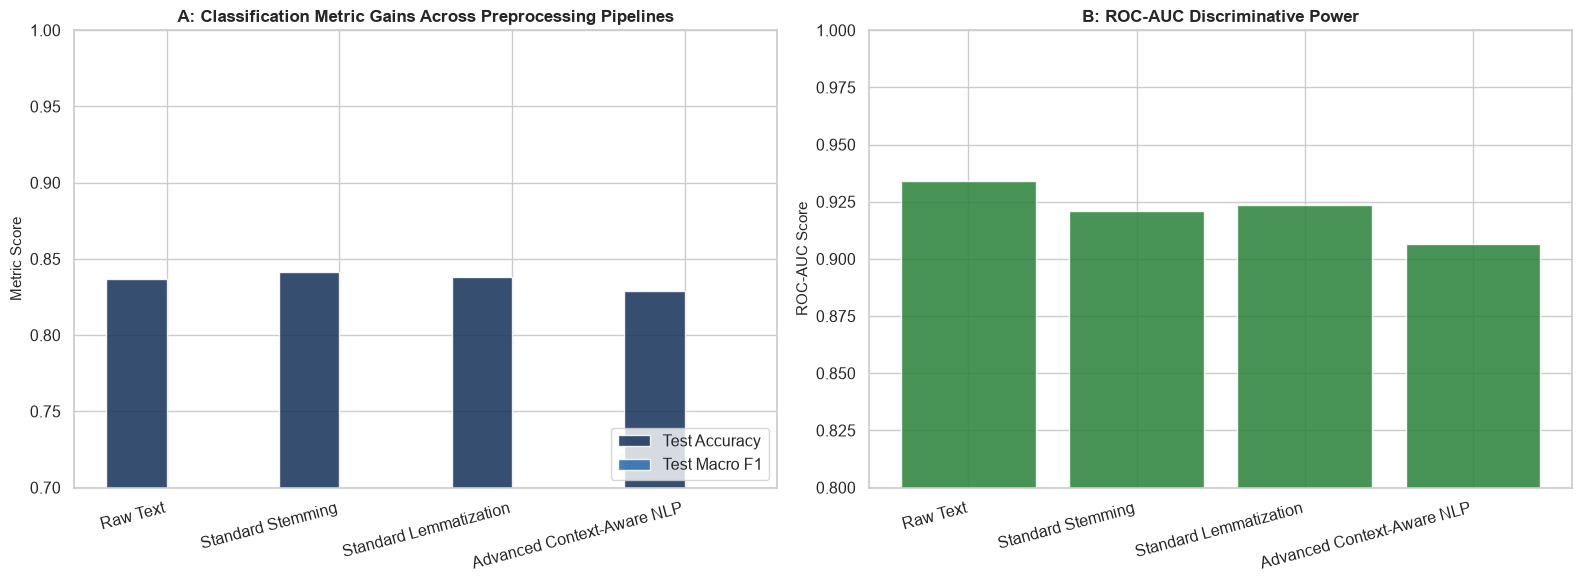

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x_pos = np.arange(len(df_bench))
width = 0.35

axes[0].bar(x_pos - width/2, df_bench['Accuracy'], width, label='Test Accuracy', color='#1A365D', alpha=0.88)
axes[0].bar(x_pos + width/2, df_bench['Macro_F1'], width, label='Test Macro F1', color='#2B6CB0', alpha=0.88)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_bench['Pipeline'], rotation=15, ha='right')
axes[0].set_ylim(0.7, 1.0)
axes[0].set_title("A: Classification Metric Gains Across Preprocessing Pipelines", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Metric Score", fontsize=11)
axes[0].legend(loc='lower right', frameon=True)

axes[1].bar(df_bench['Pipeline'], df_bench['ROC_AUC'], color='#2E8540', alpha=0.88)
axes[1].set_xticks(range(len(df_bench)))
axes[1].set_xticklabels(df_bench['Pipeline'], rotation=15, ha='right')
axes[1].set_ylim(0.8, 1.0)
axes[1].set_title("B: ROC-AUC Discriminative Power", fontsize=12, fontweight='bold')
axes[1].set_ylabel("ROC-AUC Score", fontsize=11)

plt.tight_layout()
plt.show()